1. Problem Tanımı ve Veri Toplama

1.1. İş Problemi
Kalp hastalıkları, erken değerlendirme ve uygun sağlık hizmetlerine yönlendirme gerektiren önemli sağlık sorunları arasındadır. Bu projede, bireylerin sağlık ölçümleri ve klinik özelliklerinden yararlanarak kalp hastalığı varlığını sınıflandırabilen bir makine öğrenmesi modeli geliştirmek amaçlanmaktadır.

Projenin temel hedefi, geçmiş hasta verilerindeki örüntüleri analiz ederek kalp hastalığı bulunan ve bulunmayan bireyleri ayırt etmeye yardımcı olan bir model oluşturmaktır. Böyle bir model, sağlık alanında karar destek sistemlerinin geliştirilmesine yönelik eğitim amaçlı bir örnek sunabilir.

Bu çalışma bir teşhis aracı değildir ve doktor değerlendirmesinin yerini almaz. Modelin sonuçları yalnızca akademik ve deneysel amaçlarla değerlendirilecektir.

1.2. Veri Kaynağı
Bu projede kullanılan veri seti, UCI Machine Learning Repository platformunda yayımlanan Heart Disease veri setidir. Veri setine https://archive.ics.uci.edu/dataset/45/heart+disease bağlantısı üzerinden erişilmiştir.

Veriler, platformda sunulan hazır veri dosyasından indirilmiş ve Python'un Pandas kütüphanesi kullanılarak programa aktarılmıştır. Çalışmada Cleveland veri setinin processed.cleveland.data adlı dosyası kullanılmaktadır.

Veri setinde yaş, cinsiyet, göğüs ağrısı türü, dinlenme tansiyonu, kolesterol ve maksimum kalp hızı gibi özellikler bulunmaktadır. Hedef değişken olan num, kalp hastalığı sınıflandırmasında kullanılacaktır.

Veri seti 303 gözlem içermektedir ve görece eski bir veri kaynağıdır. Bu nedenle günümüzdeki tüm hasta gruplarını temsil etmeyebilir. Ayrıca veri setinin sınırlı büyüklüğü, sonuçların farklı toplumlara ve güncel klinik koşullara genellenmesini kısıtlayabilir. Bu sınırlılıklar, model sonuçları yorumlanırken dikkate alınacaktır.

1.3. Başarı Kriteri
Projenin iş açısından başarı kriteri, kalp hastalığı olabilecek bireylerin belirlenmesine yardımcı olabilecek güvenilir bir sınıflandırma modeli geliştirmektir.

Bu hedef doğrultusunda, özellikle kalp hastalığı bulunan bireylerin doğru tespit edilmesi önemlidir. Hastalığı bulunan kişilerin yanlışlıkla hastalık yok şeklinde sınıflandırılması, modelin önemli bir sınırlılığı olacaktır.

Model değerlendirilirken yalnızca doğruluk (accuracy) oranına bakılmayacak; hastalığı bulunan bireyleri doğru belirleme başarısını gösteren recall ve diğer sınıflandırma ölçütleri de incelenecektir. Modelin sonuçları, veri setinin sınırlılıkları göz önünde bulundurularak yorumlanacaktır.

Bu çalışma kapsamında gerçek bir sağlık kuruluşunda hasta yönlendirme veya tedavi sonuçlarında iyileşme ölçülmeyecektir. Başarı, modelin mevcut veri setindeki sınıflandırma performansı ve sonuçlarının sağlık alanındaki olası kullanımına ilişkin değerlendirmeler üzerinden ele alınacaktır.

In [3]:
import pandas as pd

df = pd.read_csv(
    "processed.cleveland.data",
    header=None,
    na_values="?"
)

df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


1. Veri Setinin Yüklenmesi

Bu projede, kalp hastalığı sınıflandırması yapmak amacıyla UCI Machine Learning Repository üzerinden elde edilen Heart Disease veri seti kullanılmıştır. Veri setini okumak ve analiz etmek için Python'un Pandas kütüphanesinden yararlanılmıştır.

pd.read_csv() fonksiyonu kullanılarak processed.cleveland.data dosyası programa aktarılmıştır. Veri dosyasında sütun başlıkları bulunmadığı için header=None parametresi kullanılmıştır. Ayrıca veri setinde ? işaretiyle gösterilen değerler, na_values="?" parametresi sayesinde eksik değer olarak tanımlanmıştır.

Verinin doğru şekilde yüklendiğini kontrol etmek amacıyla df.head() komutu kullanılmış ve veri setinin ilk beş satırı görüntülenmiştir. Bu işlem, sonraki veri analizi ve temizleme aşamaları için başlangıç oluşturmuştur.

In [4]:
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "num"
]

df.columns = columns

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


2. Veri Setindeki Sütun İsimlerinin Tanımlanması
Veri dosyasında sütun başlıkları bulunmadığı için her sütuna, temsil ettiği özelliğe uygun bir isim verilmiştir. Bu işlem, verilerin daha anlaşılır hâle getirilmesini ve sonraki analizlerin kolaylaştırılmasını sağlamıştır.

Veri setindeki özellikler; yaş (age), cinsiyet (sex), göğüs ağrısı türü (cp), dinlenme tansiyonu (trestbps), kolesterol (chol), maksimum kalp hızı (thalach) gibi değişkenleri içermektedir. num sütunu ise modelin tahmin edeceği hedef değişken olarak belirlenmiştir.

Bu aşamada yalnızca sütun adları düzenlenmiş, verilerin içeriğinde herhangi bir değişiklik yapılmamıştır.

In [5]:
print("Veri setinin boyutu:", df.shape)

print("\nVeri türleri ve dolu değer sayıları:")
df.info()

print("\nEksik değer sayıları:")
print(df.isnull().sum())

Veri setinin boyutu: (303, 14)

Veri türleri ve dolu değer sayıları:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Eksik değer sayıları:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     

3. Veri Setinin Boyutunun, Veri Türlerinin ve Eksik Değerlerin İncelenmesi
Veri setinin genel yapısını anlamak amacıyla satır ve sütun sayıları, değişkenlerin veri türleri ve eksik değer durumları incelenmiştir. df.shape komutu ile veri setinin boyutu belirlenmiş, df.info() komutu ile sütunların veri türleri ve dolu değer sayıları kontrol edilmiştir. Ayrıca df.isnull().sum() komutu kullanılarak her sütundaki eksik değer sayıları hesaplanmıştır.

Veri seti 303 gözlem ve 14 sütundan oluşmaktadır. Sütunlar sayısal veri türünde görünse de bazı değişkenler kategorik anlam taşımaktadır. Bu nedenle veri türlerinin yalnızca teknik olarak değil, değişkenlerin anlamları dikkate alınarak da değerlendirilmesi gerekmektedir.

Eksik değer kontrolünde, veri dosyasında ? işaretiyle gösterilen değerler daha önce eksik değer olarak tanımlanmıştır. Bu kontrol, veri temizleme aşamasında hangi sütunlarda eksik veri bulunduğunu belirlemek ve uygun bir işlem stratejisi seçmek açısından önemlidir.

Bu aşamada henüz herhangi bir satır silinmemiş veya eksik değer doldurma işlemi yapılmamıştır. Amaç, veri setinin mevcut durumunu belirleyerek sonraki veri hazırlama adımlarına temel oluşturmaktır.

In [6]:
# Her sütundaki eksik değer sayısı
missing_values = df.isnull().sum()

# Her sütundaki eksik değer yüzdesi
missing_percent = (df.isnull().sum() / len(df)) * 100

# Sonuçları bir tabloda birleştirme
missing_table = pd.DataFrame({
    "Eksik Değer Sayısı": missing_values,
    "Eksik Değer Yüzdesi (%)": missing_percent.round(2)
})

print("Toplam eksik değer sayısı:", df.isnull().sum().sum())

missing_table[missing_table["Eksik Değer Sayısı"] > 0]

Toplam eksik değer sayısı: 6


,Eksik Değer Sayısı,Eksik Değer Yüzdesi (%)
ca,4,1.32
thal,2,0.66


2.1. Eksik Veri Analizi ve Eksik Veri Stratejisi

Veri setindeki eksik değerleri belirlemek amacıyla Pandas kütüphanesinin isnull().sum() fonksiyonu kullanılmıştır. Eksik değerlerin toplam sayısı ve her sütundaki eksik veri yüzdesi hesaplanmıştır.

Analiz sonucunda, veri setinde toplam 6 eksik değer tespit edilmiştir. Bunların 4'ü ca sütununda olup bu sütunun %1,32'sine karşılık gelmektedir. Diğer 2 eksik değer ise thal sütununda bulunmakta ve sütunun %0,66'sını oluşturmaktadır.

Veri setinde 303 gözlem bulunduğu dikkate alındığında eksik değer oranlarının düşük olduğu görülmektedir. Bu nedenle eksik değerleri ele alırken veri kaybını azaltmak ve veri setinin yapısını korumak önemlidir. ca ve thal değişkenleri kategorik anlam taşıyan özellikler olduğundan, bu değerlerin ortalama ile doldurulması uygun değildir.

Eksik değerlerin bulunduğu gözlemleri doğrudan silmek yerine, bu değişkenler için en sık görülen değerin (mod) kullanılması değerlendirilebilir. Ancak doldurma işlemi öncesinde ilgili sütunların dağılımları incelenecek ve seçilen yöntemin gerekçesi belirlenecektir. Bu işlem, veri setindeki gözlem sayısını korumayı amaçlamaktadır.

In [7]:
print("ca sütununun değer dağılımı:")
print(df["ca"].value_counts(dropna=False))

print("\nthal sütununun değer dağılımı:")
print(df["thal"].value_counts(dropna=False))

ca sütununun değer dağılımı:
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64

thal sütununun değer dağılımı:
thal
3.0    166
7.0    117
6.0     18
NaN      2
Name: count, dtype: int64


Eksik değerlerin dağılımı incelendiğinde, ca sütununda 4, thal sütununda ise 2 eksik değer bulunduğu görülmüştür. ca sütununda en sık görülen değer 0, thal sütununda ise 3'tür. Her iki sütun da kategorik anlam taşıdığından, eksik değerlerin ortalama ile doldurulması uygun değildir.

Eksik değer oranları düşük olduğu için gözlemleri doğrudan silmek yerine, en sık görülen değerle doldurma yöntemi değerlendirilecektir. Modelin değerlendirilmesinde veri sızıntısını önlemek amacıyla, doldurma değerlerinin yalnızca eğitim verisinden hesaplanması tercih edilecektir. Böylece test verisinin bilgisi modelin hazırlanması aşamasına taşınmamış olacaktır.

In [8]:
print("num sütununun değer dağılımı:")
print(df["num"].value_counts().sort_index())

num sütununun değer dağılımı:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


Hedef değişken olan num sütununun değer dağılımı incelenmiştir. Veri setinde num = 0 olan 164 kişi bulunurken, num değeri 1, 2, 3 veya 4 olan toplam 139 kişi bulunmaktadır. Bu veri setinde 0 değeri kalp hastalığı bulgusunun olmadığını, 1–4 arasındaki değerler ise farklı düzeylerde hastalık bulgularını ifade etmektedir.

Projenin amacı kalp hastalığının varlığını sınıflandırmak olduğundan, hedef değişken ikili sınıflandırmaya uygun hâle getirilecektir. Buna göre num = 0 değeri 0 (hastalık yok), num > 0 değerleri ise 1 (hastalık var) olarak kodlanacaktır. Bu dönüşüm, modelin çıktılarının daha kolay yorumlanmasını sağlayacaktır.

In [9]:
df["num"] = (df["num"] > 0).astype(int)

print("Yeni hedef değişken dağılımı:")
print(df["num"].value_counts())

print("\nSınıf yüzdeleri:")
print((df["num"].value_counts(normalize=True) * 100).round(2))

Yeni hedef değişken dağılımı:
num
0    164
1    139
Name: count, dtype: int64

Sınıf yüzdeleri:
num
0    54.13
1    45.87
Name: proportion, dtype: float64


Hedef değişkenin ikili sınıflandırmaya dönüştürülmesinden sonra veri setinde 164 kişi (%54,13) hastalık yok, 139 kişi (%45,87) hastalık var sınıfında yer almıştır. Sınıf dağılımları birbirine yakın olduğundan, veri setinde belirgin bir sınıf dengesizliği görülmemektedir.

Bu dağılım, modelin her iki sınıfı da öğrenebilmesi açısından olumlu bir durumdur. Bununla birlikte, sağlık alanındaki sınıflandırma problemlerinde yalnızca doğruluk oranı yeterli değildir. Özellikle hastalığı bulunan kişilerin doğru tespit edilme oranı (recall) da model değerlendirmesinde dikkate alınacaktır.

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop("num", axis=1)
y = df["num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Eğitim verisi boyutu:", X_train.shape)
print("Test verisi boyutu:", X_test.shape)

Eğitim verisi boyutu: (242, 13)
Test verisi boyutu: (61, 13)


Veri seti, modelin öğrenme ve değerlendirme aşamalarını birbirinden ayırmak amacıyla eğitim ve test kümelerine bölünmüştür. train_test_split() fonksiyonu kullanılarak verilerin %80'i eğitim, %20'si test için ayrılmıştır. Bölme işleminde random_state=42 kullanılarak sonuçların tekrarlanabilir olması sağlanmış, stratify=y parametresiyle hedef değişkenin sınıf oranlarının iki kümede de yaklaşık olarak korunması amaçlanmıştır.

İşlem sonucunda eğitim kümesi 242 gözlem ve 13 özellikten, test kümesi ise 61 gözlem ve 13 özellikten oluşmuştur. Eğitim kümesi modelin öğrenmesinde, test kümesi ise modelin daha önce görmediği veriler üzerindeki performansını değerlendirmede kullanılacaktır.

In [10]:
from sklearn.impute import SimpleImputer

# Eksik değerleri en sık görülen değerle doldur
imputer = SimpleImputer(strategy="most_frequent")

X_train[["ca", "thal"]] = imputer.fit_transform(
    X_train[["ca", "thal"]]
)

X_test[["ca", "thal"]] = imputer.transform(
    X_test[["ca", "thal"]]
)

print("Eğitim verisindeki eksik değer sayısı:", X_train.isnull().sum().sum())
print("Test verisindeki eksik değer sayısı:", X_test.isnull().sum().sum())

Eğitim verisindeki eksik değer sayısı: 0
Test verisindeki eksik değer sayısı: 0


Eksik değer giderilmesi, veri setindeki boş alanları uygun bir yöntemle doldurarak veriyi analize ve modellemeye hazırlamaktır.

Eksik değer konusu önemli. Veri setimizde her hastanın çeşitli bilgileri var: yaşı, kolesterolü, tansiyonu ve diğer sağlık ölçümleri.
Ancak bazı hastaların ca ve thal sütunlarında bilgi eksikti. Veri dosyasında bu bilgiler ? işaretiyle gösteriliyordu. Biz Python'da bu işaretleri eksik değer olarak tanımladık.
Veri setinde en sık görülen değerlere bakarsam mesela ca sütununda en sık görülen değer 0, thal sütununda en sık görülen değer 3. 
Daha sonra eğitim verisindeki en sık görülen değerleri kullanarak eksik alanları doldurduk. Örneğin, bir hastanın ca değeri eksikse eğitim verisinde belirlenen en sık değer o alana yazıldı.
Makine öğrenmesi modelleri bazı durumlarda eksik değerlerle doğrudan çalışamaz. Eksik değerleri uygun şekilde tamamlamak, veriyi model eğitimine hazırlar.
Bizim kodumuzun çıktısında hem eğitim hem de test verisindeki eksik değer sayısı 0 oldu. Bu, artık bu iki veri kümesinde boş değer kalmadığı anlamına geliyor.

Eksik değerlerin giderilmesi için Scikit-learn kütüphanesindeki SimpleImputer sınıfı ve most_frequent stratejisi kullanılmıştır. Bu yöntemde her sütundaki eksik değerler, eğitim verisinde en sık görülen değerle doldurulmuştur. ca ve thal sütunları kategorik anlam taşıdığı için bu yaklaşım tercih edilmiştir.

Veri sızıntısını önlemek amacıyla doldurma değerleri yalnızca eğitim verisi üzerinden hesaplanmış, ardından aynı değerler test verisine uygulanmıştır. İşlem sonrasında eğitim ve test verilerindeki toplam eksik değer sayısı ayrı ayrı kontrol edilmiş ve her iki kümede de eksik değer kalmadığı doğrulanmıştır. Böylece gözlemler silinmeden veri setinin kullanılabilirliği korunmuştur.

In [11]:
print(X_train.describe().round(2))

          age     sex      cp  trestbps    chol     fbs  restecg  thalach  \
count  242.00  242.00  242.00    242.00  242.00  242.00   242.00   242.00   
mean    54.55    0.68    3.15    130.96  249.84    0.14     0.98   149.96   
std      9.00    0.47    0.98     17.62   52.85    0.35     1.00    22.69   
min     29.00    0.00    1.00     94.00  126.00    0.00     0.00    71.00   
25%     48.00    0.00    2.25    120.00  212.00    0.00     0.00   134.50   
50%     56.00    1.00    3.00    130.00  244.50    0.00     0.00   153.50   
75%     61.00    1.00    4.00    140.00  277.75    0.00     2.00   166.00   
max     77.00    1.00    4.00    200.00  564.00    1.00     2.00   202.00   

        exang  oldpeak   slope      ca    thal  
count  242.00   242.00  242.00  242.00  242.00  
mean     0.33     1.00    1.59    0.61    4.71  
std      0.47     1.12    0.61    0.88    1.95  
min      0.00     0.00    1.00    0.00    3.00  
25%      0.00     0.00    1.00    0.00    3.00  
50%      0.0

Eğitim verisinin genel istatistiksel özelliklerini incelemek amacıyla describe() fonksiyonu kullanılmıştır. Bu fonksiyon aracılığıyla değişkenlerin gözlem sayısı, ortalaması, standart sapması, minimum ve maksimum değerleri ile çeyreklik değerleri incelenmiştir.

Analiz sonucunda eğitim verisinin 242 gözlem ve 13 özellikten oluştuğu görülmüştür. Yaş değişkeninin ortalaması 54,55, kolesterol değişkeninin ortalaması ise 249,84 olarak hesaplanmıştır. Kolesterol sütununda maksimum değerin 564 olması gibi dikkat çekici değerler belirlenmiştir. Ancak bir değerin yüksek veya düşük olması, tek başına aykırı ya da hatalı olduğunu kanıtlamaz.

Ayrıca veri setindeki bazı değişkenlerin sayısal biçimde kodlanmış kategorik değişkenler olduğu dikkate alınmıştır. Bu nedenle aykırı değer değerlendirmesi yapılırken değişkenlerin anlamları da göz önünde bulundurulacaktır.

In [12]:
# Aykırı değer incelemesinde kullanılacak ölçüm değişkenleri
numeric_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

for column in numeric_columns:
    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[column] < lower_bound) |
        (X_train[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} aykırı değer")
    print(f"Alt sınır: {lower_bound:.2f}, Üst sınır: {upper_bound:.2f}\n")

age: 0 aykırı değer
Alt sınır: 28.50, Üst sınır: 80.50

trestbps: 6 aykırı değer
Alt sınır: 90.00, Üst sınır: 170.00

chol: 5 aykırı değer
Alt sınır: 113.38, Üst sınır: 376.38

thalach: 1 aykırı değer
Alt sınır: 87.25, Üst sınır: 213.25

oldpeak: 4 aykırı değer
Alt sınır: -2.40, Üst sınır: 4.00



Değişken	Aykırı değer sayısı	            Yorum
age	             0	                Yaş değerlerinde aykırı değer tespit edilmedi.
trestbps	     6	                Dinlenme tansiyonunda 6 değer sınırların dışında.
chol	         5	                Kolesterolde 5 değer sınırların dışında.
thalach	         1	                Maksimum kalp hızında 1 değer sınırların dışında.
oldpeak	         4	                Egzersizle ilişkili ölçümde 4 değer sınırların dışında.

Toplamda bu beş değişkende 16 aykırı değer gözlemi tespit edildi. Bu, 16 farklı hasta olduğu anlamına kesin olarak gelmez; aynı hasta birden fazla değişkende aykırı değer olarak sayılmış olabilir.

Aykırı değerlerin belirlenmesi amacıyla IQR (Interquartile Range) yöntemi kullanılmıştır. Bu yöntemde birinci çeyrek (Q1) ve üçüncü çeyrek (Q3) arasındaki fark hesaplanmış, alt sınır Q1 − 1,5 × IQR ve üst sınır Q3 + 1,5 × IQR formülleriyle belirlenmiştir. Bu sınırların dışında kalan gözlemler aykırı değer adayı olarak değerlendirilmiştir.

Analiz sonucunda age değişkeninde aykırı değer bulunmamıştır. trestbps değişkeninde 6, chol değişkeninde 5, thalach değişkeninde 1 ve oldpeak değişkeninde 4 aykırı değer adayı belirlenmiştir.

Tespit edilen değerler doğrudan silinmemiştir. Sağlık verilerindeki yüksek veya düşük ölçümler gerçek klinik durumları yansıtabileceğinden, yalnızca istatistiksel sınırların dışında kalmaları bu değerlerin hatalı olduğunu göstermez. Bu nedenle gözlemleri korumak ve veri kaybını önlemek amacıyla aykırı değerler mevcut aşamada veri setinden çıkarılmamıştır.

In [13]:
print("Eğitim verisinin sütunları:")
print(X_train.dtypes)

Eğitim verisinin sütunları:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
dtype: object


Veri dönüşümü aşamasına hazırlık amacıyla eğitim verisindeki sütunların veri türleri incelenmiştir. dtypes çıktısında tüm sütunların float64 türünde olduğu görülmüştür. Ancak veri türünün sayısal olması, değişkenin mutlaka sürekli bir ölçüm olduğu anlamına gelmemektedir. Örneğin sex, cp, fbs, restecg, exang, slope, ca ve thal değişkenleri sayılarla kodlanmış kategorik veya ikili özelliklerdir.

Bu nedenle dönüşüm yöntemleri belirlenirken değişkenlerin yalnızca teknik veri türleri değil, anlamları da dikkate alınacaktır. Ölçüm değişkenleri için ölçeklendirme, kategorik değişkenler için ise uygun kodlama yöntemi değerlendirilecektir.

In [14]:
categorical_columns = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

for column in categorical_columns:
    print(f"\n{column} sütunundaki değerler:")
    print(sorted(X_train[column].unique()))


sex sütunundaki değerler:
[np.float64(0.0), np.float64(1.0)]

cp sütunundaki değerler:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]

fbs sütunundaki değerler:
[np.float64(0.0), np.float64(1.0)]

restecg sütunundaki değerler:
[np.float64(0.0), np.float64(1.0), np.float64(2.0)]

exang sütunundaki değerler:
[np.float64(0.0), np.float64(1.0)]

slope sütunundaki değerler:
[np.float64(1.0), np.float64(2.0), np.float64(3.0)]

ca sütunundaki değerler:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]

thal sütunundaki değerler:
[np.float64(3.0), np.float64(6.0), np.float64(7.0)]


Değişken	         Değerler	               Değişken türü
sex                 	0, 1               	İkili kategorik
cp	                 1, 2, 3, 4	            Çok kategorili
fbs	                    0, 1	            İkili kategorik
restecg	             0, 1, 2	            Çok kategorili
exang	               0, 1	                İkili kategorik
slope	             1, 2, 3	            Çok kategorili
ca	                0, 1, 2, 3	            Çok kategorili
thal	             3, 6, 7            	Çok kategorili

Kategorik değişkenlerin değer dağılımları incelenmiştir. sex, fbs ve exang değişkenlerinin ikili; cp, restecg, slope, ca ve thal değişkenlerinin ise birden fazla kategori içerdiği görülmüştür.

Bu değişkenlerin sayısal biçimde kodlanmış olması, aralarında her zaman matematiksel bir büyüklük ilişkisi bulunduğu anlamına gelmemektedir. Bu nedenle çok kategorili değişkenlerin modele uygun biçimde aktarılması için One-Hot Encoding yöntemi kullanılacaktır. İkili değişkenler ise mevcut 0 ve 1 kodlarıyla korunacaktır.

Ölçüm niteliğindeki değişkenler için ölçeklendirme ayrıca ele alınacaktır. Bu işlemler, verilerin makine öğrenmesi modelleri tarafından uygun biçimde kullanılmasını amaçlamaktadır.

In [15]:
from sklearn.preprocessing import OneHotEncoder

categorical_to_encode = [
    "cp",
    "restecg",
    "slope",
    "ca",
    "thal"
]

encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop="first",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(
    X_train[categorical_to_encode]
)

X_test_encoded = encoder.transform(
    X_test[categorical_to_encode]
)

encoded_columns = encoder.get_feature_names_out(
    categorical_to_encode
)

X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_columns,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_columns,
    index=X_test.index
)

X_train = pd.concat(
    [X_train.drop(columns=categorical_to_encode), X_train_encoded],
    axis=1
)

X_test = pd.concat(
    [X_test.drop(columns=categorical_to_encode), X_test_encoded],
    axis=1
)

print("Dönüşüm sonrası eğitim verisi:", X_train.shape)
print("Dönüşüm sonrası test verisi:", X_test.shape)
print("\nYeni sütunlar:")
print(X_train.columns.tolist())

Dönüşüm sonrası eğitim verisi: (242, 20)
Dönüşüm sonrası test verisi: (61, 20)

Yeni sütunlar:
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_1.0', 'restecg_2.0', 'slope_2.0', 'slope_3.0', 'ca_1.0', 'ca_2.0', 'ca_3.0', 'thal_6.0', 'thal_7.0']


Kategorik değişkenlerin makine öğrenmesi modellerinde kullanılabilmesi için One-Hot Encoding yöntemi uygulanmıştır. Bu işlemde cp, restecg, slope, ca ve thal değişkenleri ayrı gösterge sütunlarına dönüştürülmüştür. drop="first" parametresi kullanılarak her değişkenin ilk kategorisi referans olarak bırakılmış, gereksiz sütun tekrarının azaltılması amaçlanmıştır.

Kodlayıcı yalnızca eğitim verisi üzerinde öğrenilmiş ve aynı dönüşüm test verisine uygulanmıştır. Böylece eğitim ve test kümelerinde aynı sütun yapısı korunmuştur. Dönüşüm sonucunda eğitim verisi 242 satır ve 20 sütundan, test verisi ise 61 satır ve 20 sütundan oluşmuştur. İkili kategorik değişkenler olan sex, fbs ve exang mevcut 0–1 kodlarıyla korunmuştur.

In [17]:
from sklearn.preprocessing import StandardScaler

In [18]:
numeric_columns = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

scaler = StandardScaler()

X_train[numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)

X_test[numeric_columns] = scaler.transform(
    X_test[numeric_columns]
)

print("Ölçeklendirme sonrası eğitim verisi:")
print(X_train[numeric_columns].describe().round(2))

Ölçeklendirme sonrası eğitim verisi:
          age  trestbps    chol  thalach  oldpeak
count  242.00    242.00  242.00   242.00   242.00
mean    -0.00     -0.00    0.00    -0.00     0.00
std      1.00      1.00    1.00     1.00     1.00
min     -2.85     -2.10   -2.35    -3.49    -0.89
25%     -0.73     -0.62   -0.72    -0.68    -0.89
50%      0.16     -0.05   -0.10     0.16    -0.18
75%      0.72      0.51    0.53     0.71     0.54
max      2.50      3.93    5.96     2.30     4.64


Sayısal ölçüm değişkenlerinin farklı ölçeklerde bulunmasının model performansını olumsuz etkilemesini önlemek amacıyla StandardScaler yöntemi uygulanmıştır. Bu kapsamda age, trestbps, chol, thalach ve oldpeak değişkenleri ölçeklendirilmiştir.

Ölçeklendirme parametreleri yalnızca eğitim verisi üzerinden hesaplanmış, ardından aynı dönüşüm test verisine uygulanmıştır. Böylece test verisinin bilgisi ölçeklendirme parametrelerinin hesaplanmasına dâhil edilmemiştir.

İşlem sonrasında eğitim verisindeki ilgili değişkenlerin ortalamalarının yaklaşık 0, standart sapmalarının ise 1 olduğu görülmüştür. Bu sonuç, ölçeklendirme işleminin başarılı olduğunu göstermektedir. Ölçeklendirme, gözlemlerin gerçek değerlerini silmez; değişkenleri farklı bir ölçekte ifade eder.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

Accuracy: 0.8689
Precision: 0.8333
Recall: 0.8929
F1 Score: 0.8621


Logistic Regression Test Sonuçları
Accuracy 86,89 %                                     Precision 83,33 %
Genel Doğruluk                                       Pozitif Tahminlerin Doğruluğu

Recall                                               F1 Score
89,29 %                                              86,21 %
Hastalığı olanların yakalanma oranı                  Precision ve Recall Dengesi

İlk Model: Logistic Regression

Veri hazırlama işlemlerinin ardından ilk sınıflandırma modeli olarak Logistic Regression kullanılmıştır. Model, eğitim verisi üzerinde eğitilmiş ve daha önce eğitim sırasında kullanılmayan test verisi üzerinde değerlendirilmiştir. Performansı ölçmek amacıyla Accuracy, Precision, Recall ve F1 Score metrikleri hesaplanmıştır.

Modelin test sonuçlarında Accuracy 0,8689 (%86,89), Precision 0,8333 (%83,33), Recall 0,8929 (%89,29) ve F1 Score 0,8621 (%86,21) olarak elde edilmiştir.

Bu sonuçlara göre model, test verisindeki gözlemlerin yaklaşık %86,89'unu doğru sınıflandırmıştır. Recall değerinin %89,29 olması, hastalık sınıfında bulunan bireylerin önemli bir bölümünün doğru tespit edildiğini göstermektedir. Precision değerinin %83,33 olması ise modelin hastalık var şeklinde tahmin ettiği gözlemlerin büyük bölümünün gerçekten hastalık sınıfında olduğunu ifade etmektedir.

Bununla birlikte, veri setinin 303 gözlemden oluşması ve kullanılan test kümesinin yalnızca 61 gözlem içermesi nedeniyle sonuçlar dikkatli yorumlanmalıdır. Bu performans, modelin gerçek klinik koşullarda aynı doğrulukla çalışacağını kanıtlamaz. Modelin daha kapsamlı değerlendirilmesi için diğer sınıflandırma algoritmalarıyla karşılaştırılması gerekmektedir.

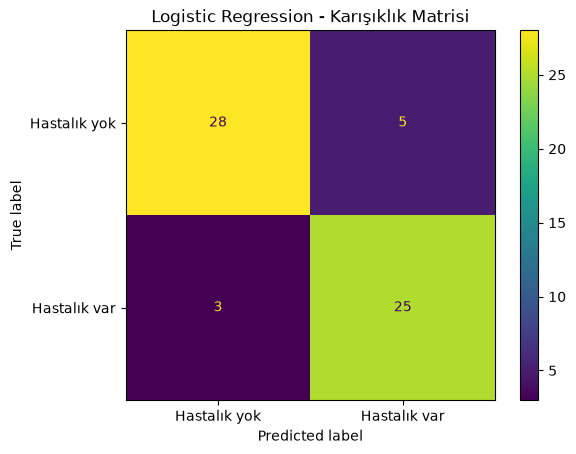

Karışıklık matrisi:
[[28  5]
 [ 3 25]]


In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Hastalık yok", "Hastalık var"]
)

disp.plot()
plt.title("Logistic Regression - Karışıklık Matrisi")
plt.show()

print("Karışıklık matrisi:")
print(cm)

- 28: Hastalığı olmayan 28 kişiyi doğru şekilde hastalık yok olarak sınıflandırdı.
- 5: Hastalığı olmayan 5 kişiyi yanlışlıkla hastalık var olarak sınıflandırdı.
- 3: Hastalığı olan 3 kişiyi yanlışlıkla hastalık yok olarak sınıflandırdı. Sağlık bağlamında özellikle dikkat etmemiz gereken sonuç budur.
- 25: Hastalığı olan 25 kişiyi doğru şekilde hastalık var olarak sınıflandırdı.
Model toplamda \(28+25=53\) kişiyi doğru, \(5+3=8\) kişiyi yanlış sınıflandırmış. Bu da yaklaşık %86,89 doğruluk demektir.

Karışıklık matrisi, Logistic Regression modelinin test verileri üzerindeki doğru ve yanlış sınıflandırmalarını incelemek amacıyla kullanılmıştır. Model, hastalığı bulunmayan 33 kişinin 28'ini doğru sınıflandırırken 5 kişiyi yanlışlıkla hastalığı var olarak tahmin etmiştir. Hastalığı bulunan 28 kişinin ise 25'i doğru, 3'ü yanlış sınıflandırılmıştır.

Modelin test verisindeki doğruluk oranı %86,89'dur. Bununla birlikte, sağlık alanında yalnızca doğruluk oranına bakmak yeterli değildir. Hastalığı bulunan kişilerin hastalığı yok şeklinde sınıflandırılması önemli bir hata türüdür. Bu çalışmada 3 kişinin bu şekilde yanlış sınıflandırıldığı görülmüştür. Sonuçlar, modelin sınırlı büyüklükteki test verisi üzerinde elde edilmiştir ve gerçek klinik kullanım için yeterli kanıt oluşturmaz.

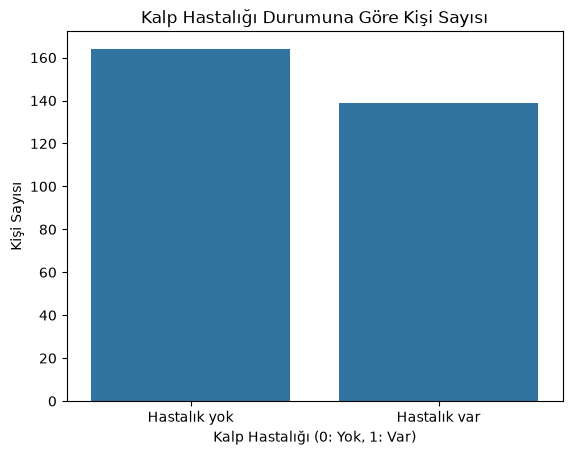

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="num")

plt.title("Kalp Hastalığı Durumuna Göre Kişi Sayısı")
plt.xlabel("Kalp Hastalığı (0: Yok, 1: Var)")
plt.ylabel("Kişi Sayısı")
plt.xticks([0, 1], ["Hastalık yok", "Hastalık var"])
plt.show()

3. bölüm olan Keşifsel Veri Analizinde (EDA) önce hastalık bulunan ve bulunmayan kişi sayılarını bir grafikle gösterdim. Kalp hastalığı durumunun veri setindeki dağılımı incelendiğinde, 303 gözlemin 164'ünde kalp hastalığı bulunmadığı, 139'unda ise kalp hastalığı bulunduğu görülmüştür. Bu değerler sırasıyla yaklaşık %54,13 ve %45,87 oranlarına karşılık gelmektedir.

İki sınıfın gözlem sayıları birbirine yakın olduğundan, veri setinde belirgin bir sınıf dengesizliği bulunmamaktadır.

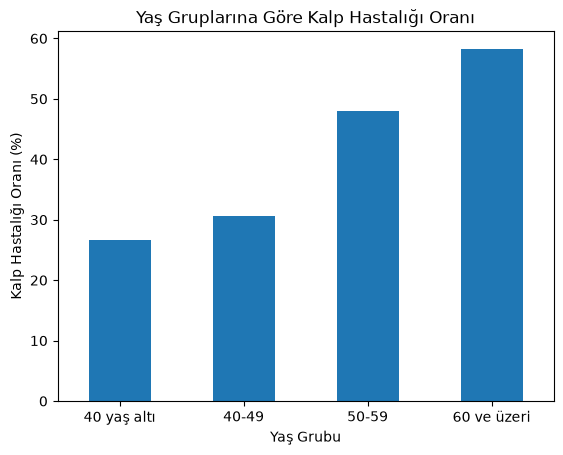

age_group
40 yaş altı    26.67
40-49          30.56
50-59          48.00
60 ve üzeri    58.24
Name: num, dtype: float64


In [22]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 40, 50, 60, 100],
    labels=["40 yaş altı", "40-49", "50-59", "60 ve üzeri"],
    right=False
)

age_disease_rate = df.groupby(
    "age_group", observed=False
)["num"].mean() * 100

age_disease_rate.plot(kind="bar")

plt.title("Yaş Gruplarına Göre Kalp Hastalığı Oranı")
plt.xlabel("Yaş Grubu")
plt.ylabel("Kalp Hastalığı Oranı (%)")
plt.xticks(rotation=0)
plt.show()

print(age_disease_rate.round(2))

Yaş gruplarına göre kalp hastalığı oranları incelendiğinde, yaş grubu yükseldikçe hastalık bulunan bireylerin oranının genel olarak arttığı görülmüştür. 40 yaş altındaki grupta bu oran %26,67, 40–49 yaş grubunda %30,56, 50–59 yaş grubunda %48,00 ve 60 yaş ve üzerindeki grupta %58,24 olarak hesaplanmıştır.

Bu bulgu, incelenen veri setinde yaş ile kalp hastalığı varlığı arasında olası bir ilişki bulunduğunu göstermektedir. Bununla birlikte, bu sonuç tek başına nedensellik anlamına gelmemektedir. 

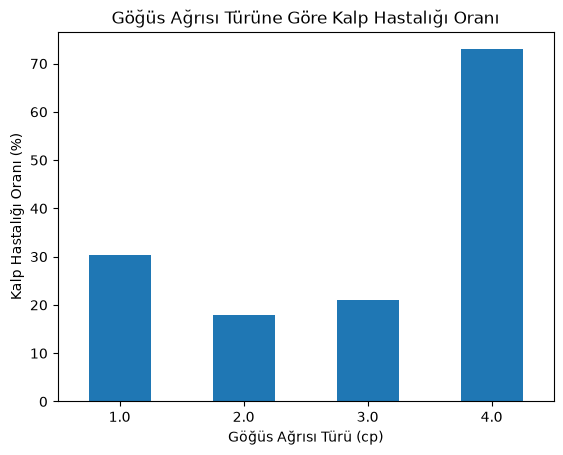

cp
1.0    30.43
2.0    18.00
3.0    20.93
4.0    72.92
Name: num, dtype: float64


In [23]:
cp_disease_rate = df.groupby("cp")["num"].mean() * 100

cp_disease_rate.plot(kind="bar")

plt.title("Göğüs Ağrısı Türüne Göre Kalp Hastalığı Oranı")
plt.xlabel("Göğüs Ağrısı Türü (cp)")
plt.ylabel("Kalp Hastalığı Oranı (%)")
plt.xticks(rotation=0)
plt.show()

print(cp_disease_rate.round(2))

Göğüs ağrısı türüne göre kalp hastalığı oranları incelendiğinde, kategoriler arasında farklılıklar olduğu görülmüştür. cp = 1 grubunda hastalık oranı %30,43, cp = 2 grubunda %18,00, cp = 3 grubunda %20,93 ve cp = 4 grubunda %72,92 olarak hesaplanmıştır. En yüksek oran cp = 4 grubunda gözlenmiştir.

Bu bulgu, göğüs ağrısı türü değişkeninin kalp hastalığı sınıflandırması açısından yararlı bir özellik olabileceğini düşündürmektedir. Ancak bu oranlar yalnızca incelenen veri setini yansıtmaktadır. Kategoriler sayısal kodlarla temsil edildiğinden, kodların anlamı dikkate alınmadan klinik yorum yapılmamalıdır.

Şimdi 4. bölüm olan Modelleme ve Değerlendirme bölümüne geçiyorum. 4.1'deki Metrik seçimi kısmını zaten yukarıda yaptım. (Logistic Regression ve Karışıklık Matrisi)
4.1 Model Karşılaştırmayla devam ediyorum. 

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_model = RandomForestClassifier(
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Sonuçları")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_rf), 4))

Random Forest Sonuçları
Accuracy: 0.9016
Precision: 0.8667
Recall: 0.9286
F1-Score: 0.8966


Bu çalışmada ilk olarak Logistic Regression modeli kurulmuş, ardından sonuçları karşılaştırmak amacıyla Random Forest modeli denenmiştir. Logistic Regression modelinde Accuracy %86,89, Precision %83,33, Recall %89,29 ve F1-Score %86,21 olarak elde edilmiştir. Random Forest modelinde ise bu değerler sırasıyla %90,16, %86,67, %92,86 ve %89,66 olmuştur.

Random Forest modelinin tüm değerlendirme ölçütlerinde daha yüksek sonuç vermesi nedeniyle bu model hiperparametre optimizasyonu için aday model olarak seçilmiştir. Özellikle Recall değerindeki artış, kalp hastalığı bulunan bireylerin tespit edilmesi hedefi açısından olumlu değerlendirilmiştir. Bununla birlikte, test veri setinin küçük olması nedeniyle sonuçların farklı veri örneklerinde değişebileceği göz önünde bulundurulmalıdır. Modellerin performansı çapraz doğrulama ve hiperparametre optimizasyonu aşamalarında da incelenecektir.

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("En iyi parametreler:")
print(grid_search.best_params_)

print("En iyi çapraz doğrulama F1-Score:")
print(round(grid_search.best_score_, 4))

En iyi parametreler:
{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
En iyi çapraz doğrulama F1-Score:
0.7875


Random Forest modelinin performansını iyileştirmek amacıyla GridSearchCV yöntemi kullanılmıştır. Bu süreçte n_estimators, max_depth, min_samples_split ve min_samples_leaf parametrelerinin farklı kombinasyonları denenmiştir. Toplam 24 parametre kombinasyonu 5 katlı çapraz doğrulama ile değerlendirilmiştir.

En iyi parametreler n_estimators=100, max_depth=None, min_samples_split=5 ve min_samples_leaf=2 olarak belirlenmiştir. Bu kombinasyonla elde edilen en iyi ortalama çapraz doğrulama F1-Score değeri 0,7875'tir. Bu sonuç, modelin eğitim verisinin farklı bölümlerindeki performansını değerlendirmek için kullanılmıştır. Optimize edilmiş modelin nihai başarısı, daha önce eğitim sırasında kullanılmamış test verisi üzerinde ayrıca ölçülecektir.

In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

best_rf = grid_search.best_estimator_

y_pred_best_rf = best_rf.predict(X_test)

print("Optimize Edilmiş Random Forest Sonuçları")
print("Accuracy:", round(accuracy_score(y_test, y_pred_best_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_best_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_best_rf), 4))
print("F1-Score:", round(f1_score(y_test, y_pred_best_rf), 4))

print("\nKarışıklık Matrisi:")
print(confusion_matrix(y_test, y_pred_best_rf))

Optimize Edilmiş Random Forest Sonuçları
Accuracy: 0.9016
Precision: 0.8667
Recall: 0.9286
F1-Score: 0.8966

Karışıklık Matrisi:
[[29  4]
 [ 2 26]]


- 29: Hastalık bulunmayan kişiler doğru sınıflandırılmış.
- 4: Hastalık bulunmayan kişiler yanlışlıkla hastalık var olarak tahmin edilmiş.
- 2: Hastalığı bulunan kişiler yanlışlıkla hastalık yok olarak tahmin edilmiş.
- 26: Hastalığı bulunan kişiler doğru sınıflandırılmış.
Bu sonuçlara göre test verisindeki 61 kişinin 55'i doğru sınıflandırılmıştır. Hastalığı bulunan 28 kişinin 26'sı doğru tespit edilmiştir.

Hiperparametre optimizasyonundan sonra elde edilen Random Forest modeli, test verisinde %90,16 Accuracy, %86,67 Precision, %92,86 Recall ve %89,66 F1-Score değerlerine ulaşmıştır. Karışıklık matrisi incelendiğinde, hastalığı bulunmayan 33 kişinin 29'unun doğru sınıflandırıldığı, hastalığı bulunan 28 kişinin ise 26'sının doğru tespit edildiği görülmüştür.

Optimizasyon öncesi ve sonrası test metriklerinin aynı kalması, denenen parametre değişikliklerinin test performansında ölçülebilir bir iyileşme sağlamadığını göstermektedir. Bununla birlikte, çapraz doğrulamada elde edilen en iyi ortalama F1-Score değeri 0,7875'tir. Bu değer ile test setindeki F1-Score arasındaki fark, modelin farklı veri örneklerinde nasıl performans göstereceğinin daha ayrıntılı incelenmesi gerektiğini ortaya koymaktadır. Test setinin küçük olması nedeniyle sonuçlar dikkatli yorumlanmalıdır.

In [1]:
print("Jupyter çalışıyor")

Jupyter çalışıyor


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

rf = RandomForestClassifier(
    n_estimators=50,
    random_state=42,
    n_jobs=1
)

scores = cross_val_score(
    rf,
    X_train,
    y_train,
    cv=3,
    scoring="f1",
    n_jobs=1
)

print("Her katın F1-Score değerleri:", scores.round(4))
print("Ortalama F1-Score:", round(scores.mean(), 4))

Her katın F1-Score değerleri: [0.8108 0.7222 0.7838]
Ortalama F1-Score: 0.7723


- 1. kat: 0.8108 — en yüksek F1 değeri.
- 2. kat: 0.7222 — en düşük F1 değeri.
- 3. kat: 0.7838 — diğer iki sonucun arasında.
- Ortalama: 0.7723 — modelin bu üç doğrulama katındaki ortalama F1 performansı.
Bu değerler, modelin farklı veri bölümlerinde benzer düzeyde performans gösterdiğini, ancak sonuçların bir miktar değiştiğini gösteriyor.

4.4. Çapraz Doğrulama ve Modelin Genellenebilirliği

Modelin farklı veri bölümlerindeki performansını değerlendirmek amacıyla 3 katlı çapraz doğrulama (3-Fold Cross-Validation) uygulanmıştır. Her kat için F1-Score değerleri sırasıyla 0.8108, 0.7222 ve 0.7838 olarak elde edilmiştir. Ortalama F1-Score değeri 0.7723'tür.

Sonuçlar, model performansının veri bölümlerine göre bir miktar değişebildiğini göstermektedir. Çapraz doğrulama, modelin tek bir eğitim-test ayrımına bağlı kalmadan değerlendirilmesine yardımcı olur. Bununla birlikte, çapraz doğrulama sonuçları tek başına aşırı öğrenmenin (overfitting) bulunup bulunmadığını kesin olarak kanıtlamaz. Bunun için eğitim ve doğrulama performanslarının birlikte incelenmesi gerekir.

thal        0.161612
cp          0.134534
ca          0.124105
thalach     0.120471
oldpeak     0.096832
age         0.077396
chol        0.065154
trestbps    0.060061
exang       0.051976
slope       0.044101
dtype: float64


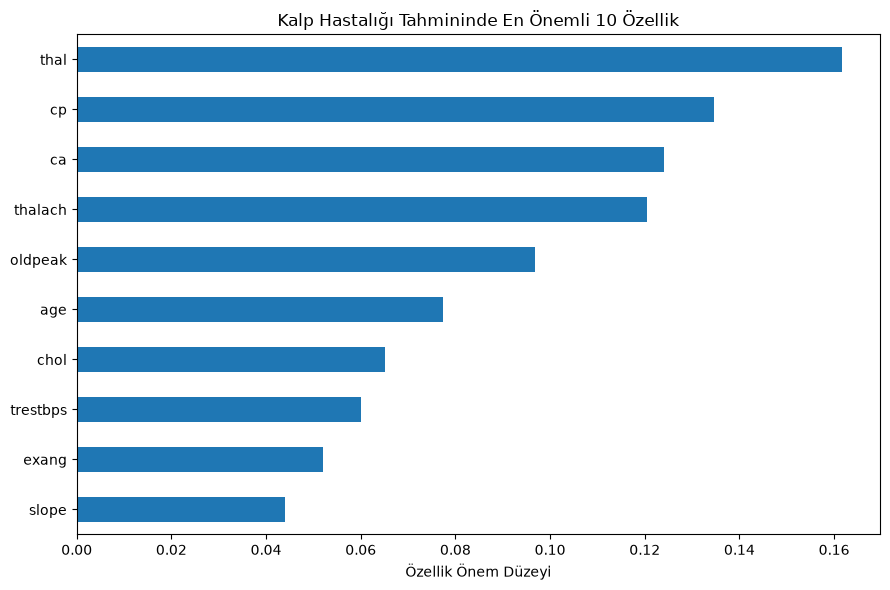

In [18]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

rf_section5 = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

rf_section5.fit(X_train, y_train)

importance = pd.Series(
    rf_section5.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(10))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)
plt.title("Kalp Hastalığı Tahmininde En Önemli 10 Özellik")
plt.xlabel("Özellik Önem Düzeyi")
plt.tight_layout()
plt.show()


5.1. Model Yorumlama: Feature Importance

Random Forest modelinin tahminlerini yorumlamak amacıyla özellik önem düzeyleri incelenmiştir. Sonuçlara göre en yüksek önem değerine sahip özellik thal (0.1616) olmuştur. Bunu cp (0.1345), ca (0.1241), thalach (0.1205) ve oldpeak (0.0968) izlemiştir.

Bulgular, modelin tahminlerinde göğüs ağrısı türü, görüntüleme bulguları ve egzersiz sırasında ölçülen bazı klinik değişkenlerden yararlandığını göstermektedir. Yaş (0.0774), kolesterol (0.0652) ve dinlenme kan basıncı (0.0601) da modelin kullandığı özellikler arasındadır.

Özellik önem düzeyleri, modelin tahminleri oluştururken hangi değişkenlerden daha fazla yararlandığını gösterir. Ancak bu değerler değişkenler arasındaki nedensel ilişkiyi kanıtlamaz ve tek bir hastaya ait tahminin nedenini tek başına açıklamaz. Bu nedenle sonuçlar, modelin kararlarını anlamaya yönelik bir araç olarak değerlendirilmiştir.

In [19]:
print("shap mevcut mu:", "shap" in globals())

shap mevcut mu: False


In [20]:
print("Model mevcut:", "rf_section5" in globals())
print("Test verisi mevcut:", "X_test" in globals())

Model mevcut: True
Test verisi mevcut: True


In [21]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Users\adelikan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Gerçek sınıf: 0
Model tahmini: 0


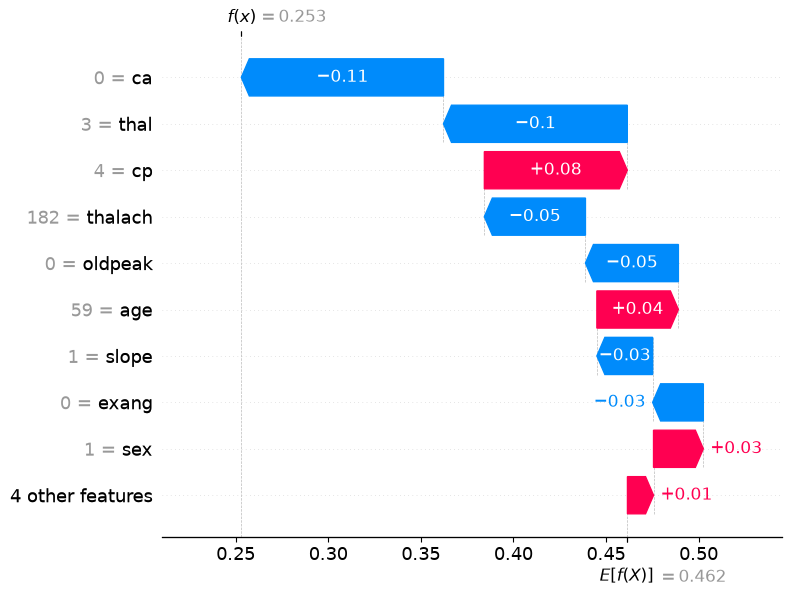

In [22]:
import shap
import matplotlib.pyplot as plt

# Random Forest modeli için SHAP açıklayıcısı
explainer = shap.TreeExplainer(rf_section5)

# Test verisinden tek bir örnek seç
sample = X_test.iloc[[0]]

# SHAP değerlerini hesapla
shap_values = explainer(sample)

# İkili sınıflandırmada hastalık sınıfının açıklamasını göster
print("Gerçek sınıf:", y_test.iloc[0])
print("Model tahmini:", rf_section5.predict(sample)[0])

shap.plots.waterfall(shap_values[0, :, 1], max_display=10)


Grafiğin üst kısmında Model tahmini: 0 yazıyor. Bizim kodlamamızda:
- 0 = Kalp hastalığı yok
- 1 = Kalp hastalığı var
Model, incelediğimiz örneği kalp hastalığı yok olarak tahmin etmiş.

Grafikteki \(E[f(X)] = 0.462\), modelin başlangıç tahmin değerini; \(f(x) = 0.253\) ise bu örnek için özelliklerin katkıları hesaba katıldıktan sonraki değeri gösteriyor. Bu grafikte değerler olasılık ölçeğinde gösterildiği için son değeri yaklaşık %25,3 olarak yorumlayabiliriz.

5.2. SHAP ile Tek Bir Tahminin Açıklanması

Modelin bireysel tahminlerini yorumlamak amacıyla SHAP (SHapley Additive exPlanations) yöntemi kullanılmıştır. Analiz kapsamında test veri setinden bir örnek seçilmiş ve modelin bu örnek için neden belirli bir tahminde bulunduğu incelenmiştir.

İncelenen örnek için modelin tahmini 0, yani kalp hastalığı yok şeklindedir. SHAP waterfall grafiğinde ca, thal, thalach ve oldpeak değişkenlerinin tahmini hastalık sınıfından uzaklaştıran katkılar sağladığı görülmüştür. Buna karşılık cp, age ve sex değişkenleri tahmini hastalık sınıfına doğru etkilemiştir.

Bu analiz, modelin tek bir tahmini oluştururken farklı özellikleri birlikte değerlendirdiğini göstermektedir. SHAP sonuçları modelin karar sürecini açıklamaya yardımcı olur; ancak klinik bir tanının yerine geçmez ve değişkenler arasında nedensellik olduğunu kanıtlamaz.

In [23]:
sample = X_test.iloc[[0]]

prediction = rf_section5.predict(sample)[0]
probabilities = rf_section5.predict_proba(sample)[0]

print("Model tahmini:", prediction)
print("Hastalık yok sınıfı:", round(probabilities[0] * 100, 2), "%")
print("Hastalık var sınıfı:", round(probabilities[1] * 100, 2), "%")

Model tahmini: 0
Hastalık yok sınıfı: 74.69 %
Hastalık var sınıfı: 25.31 %


Geliştirilen Random Forest modeli, test veri setindeki örneklerden biri için kalp hastalığı yok sınıfını tahmin etmiştir. Modelin sınıf tahmin değerleri, hastalık yok sınıfı için %74,69 ve hastalık var sınıfı için %25,31 olarak elde edilmiştir. Bu sonuç, modelin ilgili örneği hastalık yok sınıfına atadığını göstermektedir. Bununla birlikte, model çıktıları klinik tanı veya gelecekteki hastalık riskinin kesin ölçümü olarak değerlendirilmemelidir.

6.1. Projenin Kısıtları ve Zayıf Yönleri

1. Veri setinin sınırlı olması: Cleveland kalp hastalığı veri seti 303 gözlem ve 13 özellik içermektedir. Bu veri miktarı, farklı hasta gruplarını temsil etmek ve modelin genellenebilirliğini kapsamlı biçimde değerlendirmek için sınırlıdır.

2. Verilerin eski olması: Kullanılan veri seti geçmiş yıllara aittir. Günümüzdeki hasta profillerini, tanı yöntemlerini ve sağlık hizmetlerindeki gelişmeleri tam olarak temsil etmeyebilir.

3. Genellenebilirlik: Modelin performansı mevcut veri seti üzerinde değerlendirilmiştir. Farklı hastanelerden veya farklı hasta gruplarından alınan bağımsız veriler üzerinde doğrulama yapılmamıştır. Bu nedenle modelin gerçek sağlık ortamlarında aynı başarıyı göstereceği garanti edilemez.

4. Aşırı öğrenme kontrolünün sınırlı olması: Modelin test F1-Score değeri 0.8966, üç katlı çapraz doğrulamadaki ortalama F1-Score değeri ise 0.7723 olarak hesaplanmıştır. Ancak eğitim F1-Score değeriyle doğrudan karşılaştırma tamamlanmadığından aşırı öğrenme durumu kesin olarak değerlendirilememiştir.

5. Klinik kullanım kısıtı: Model, veri setindeki mevcut kalp hastalığı durumunu sınıflandırmak üzere geliştirilmiştir; gelecekte hastalığa yakalanma riskini tahmin etmek için tasarlanmamıştır. Ayrıca modelin tahminleri klinik tanı yerine geçmez.

6. Özelliklerin yorumlanması: Feature Importance ve SHAP analizleri modelin tahminlerinde hangi özelliklerden yararlandığını açıklamaya yardımcı olmuştur. Ancak bu yöntemler değişkenler arasında nedensellik olduğunu kanıtlamaz.

6.2. Gelecek Çalışmalar

Projeye bir ay daha ayrılması durumunda aşağıdaki geliştirmeler yapılabilir:

1. Daha kapsamlı veri toplama: Farklı hastanelerden ve daha geniş hasta gruplarından elde edilen güncel veriler kullanılarak modelin temsil gücü artırılabilir.

2. Farklı modellerin karşılaştırılması: Random Forest ve Logistic Regression modellerine ek olarak Gradient Boosting ve diğer uygun sınıflandırma algoritmaları değerlendirilebilir. Modeller aynı veri bölünmesi ve aynı değerlendirme ölçütleriyle karşılaştırılabilir.

3. Daha kapsamlı doğrulama: Eğitim ve test performansları karşılaştırılarak aşırı öğrenme incelenebilir. Ayrıca bağımsız bir veri seti üzerinde test yapılarak modelin yeni verilerdeki başarısı değerlendirilebilir.

4. Modelin açıklanabilirliğinin geliştirilmesi: SHAP analizleri farklı örnekler üzerinde uygulanabilir. Böylece modelin farklı tahminlerde hangi özelliklerden nasıl etkilendiği daha kapsamlı biçimde incelenebilir.

5. Kullanıcı arayüzü geliştirilmesi: Modeli deneysel olarak kullanmayı sağlayan basit bir web arayüzü hazırlanabilir. Kullanıcılar örnek verileri girerek modelin sınıflandırmasını ve ilgili açıklamaları görebilir.

6. API geliştirilmesi: Modelin bir uygulama üzerinden kullanılabilmesi için bir API hazırlanabilir. Ancak gerçek sağlık ortamında kullanım öncesinde bağımsız klinik doğrulama, veri güvenliği ve gerekli yasal gereklilikler değerlendirilmelidir.

Sonuç olarak bu proje, makine öğrenmesi yöntemlerinin kalp hastalığı verilerinin sınıflandırılmasında nasıl kullanılabileceğini göstermektedir. Bununla birlikte, modelin gerçek dünyada güvenilir biçimde kullanılabilmesi için daha geniş veri setleriyle doğrulama yapılması ve performansının farklı hasta gruplarında incelenmesi gerekmektedir.